TITANIC DATASET LOADED SUCCESSFULLY

First 5 Rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4   

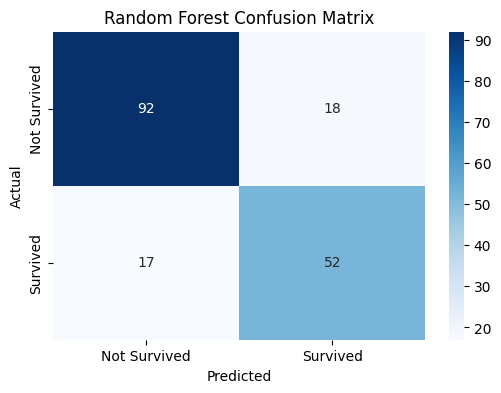


CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.84      0.84      0.84       110
           1       0.74      0.75      0.75        69

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.81      0.80      0.80       179


FEATURE IMPORTANCE:
Fare                      0.239259
Age                       0.215423
Title_Mr                  0.119998
Sex                       0.106309
Pclass                    0.076665
SibSp                     0.050044
Title_Miss                0.037763
Title_Mrs                 0.035867
Parch                     0.033328
TicketPrefix_NONE         0.011952
Title_Master              0.009837
TicketPrefix_STONO        0.009292
TicketPrefix_PC           0.006406
TicketPrefix_A            0.006335
TicketPrefix_WC           0.006160
TicketPrefix_CA           0.004631
Title_Rev                 0.004258
TicketPrefix_SWPP         0.00258

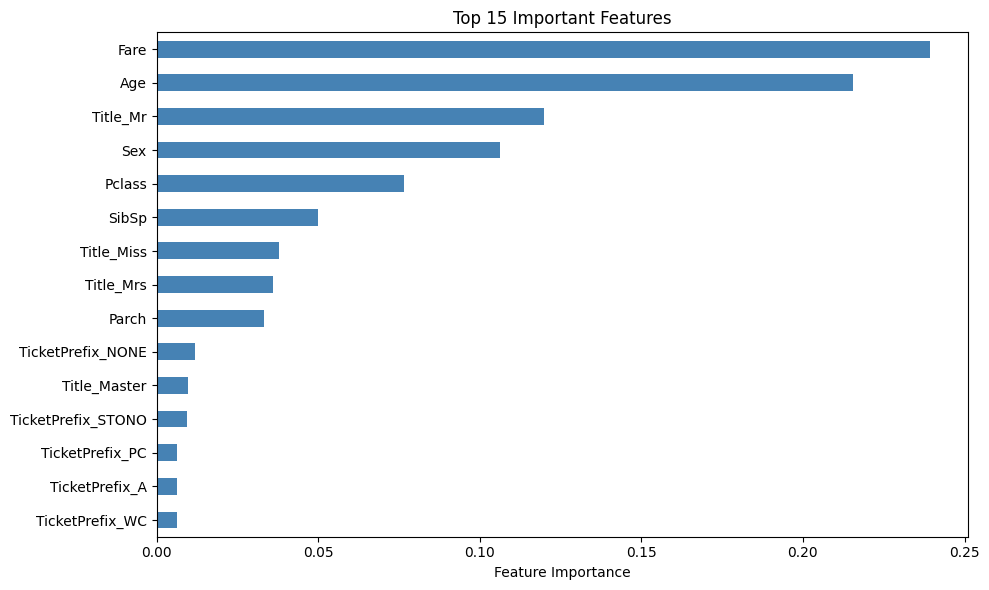

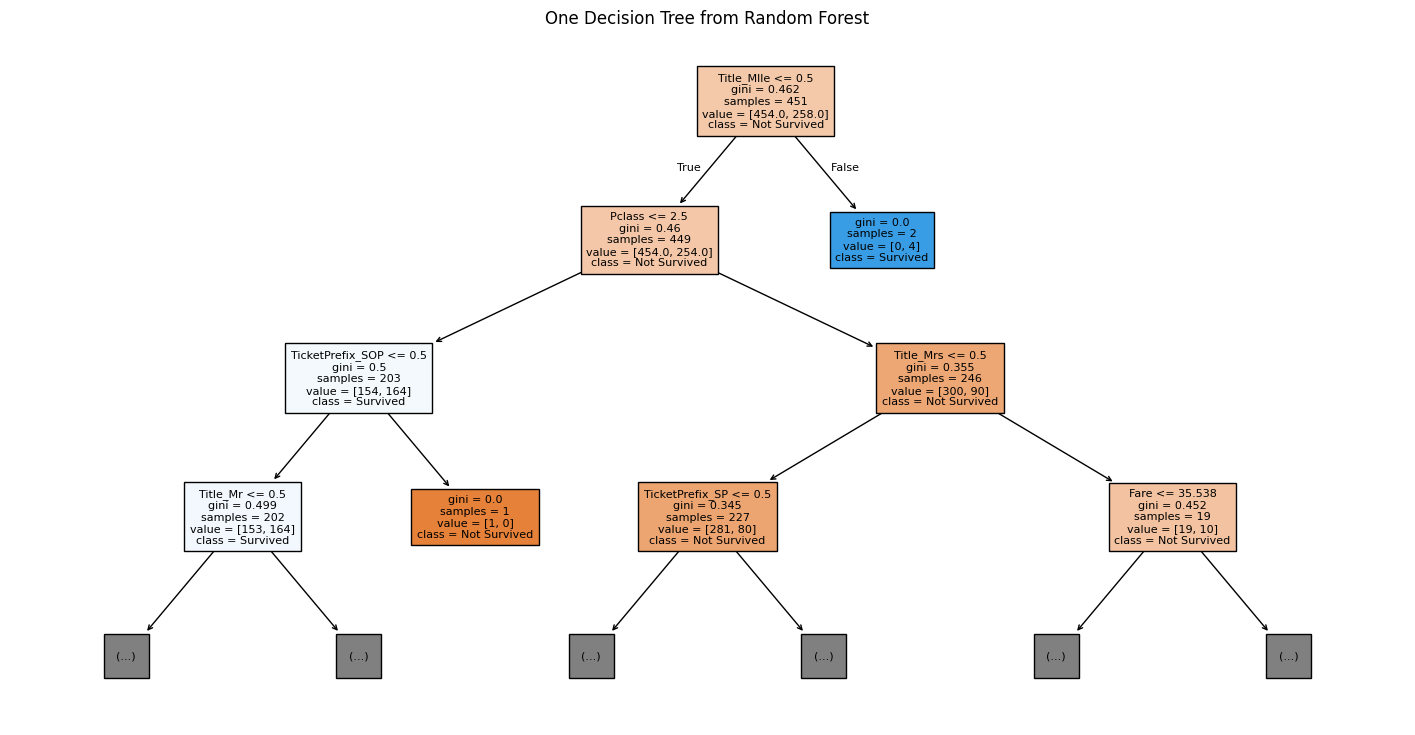


NEW PASSENGER PREDICTION:
Passenger Survived


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: U


RANDOM FOREST MAJORITY VOTING:
Survived Votes: 100
Not Survived Votes: 0

FINAL PREDICTION: 1

PROJECT COMPLETED SUCCESSFULLY!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: U

In [ ]:

# =====================================================
# RANDOM FOREST CLASSIFICATION USING TITANIC DATASET
# =====================================================

# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
from sklearn.tree import plot_tree

# STEP 2: LOAD DATASET

df = pd.read_csv('/content/Titanic-Dataset.csv')

print("TITANIC DATASET LOADED SUCCESSFULLY")
print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

# STEP 3: SELECT REQUIRED ATTRIBUTES

columns = [
    'PassengerId', 'Survived', 'Pclass', 'Name',
    'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare'
]

df = df[columns].copy()

# STEP 4: DATA PREPROCESSING

# Extract useful titles from Name
df['Title'] = df['Name'].str.extract(
    r',\s*([^.]*)\.', expand=False
).fillna('Unknown')

# Extract useful prefix from Ticket
df['TicketPrefix'] = (
    df['Ticket'].fillna('Unknown')
    .astype(str)
    .str.replace(r'[0-9./ ]', '', regex=True)
    .replace('', 'NONE')
)

# Encode categorical columns
df['Sex'] = df['Sex'].map({
    'male': 0,
    'female': 1
})

df = pd.get_dummies(
    df,
    columns=['Title', 'TicketPrefix'],
    dtype=int
)

# Remove ID and original text columns
df = df.drop(
    ['PassengerId', 'Name', 'Ticket'],
    axis=1
)

# Handle missing values
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Fare'] = df['Fare'].fillna(df['Fare'].median())
df['Sex'] = df['Sex'].fillna(df['Sex'].mode()[0])

print("\nPREPROCESSED DATASET:")
print(df.head())

# STEP 5: SEPARATE FEATURES AND TARGET

X = df.drop('Survived', axis=1)
y = df['Survived']

print("\nSelected Features:")
print(X.columns.tolist())

print("\nTarget: Survived")

# STEP 6: CALCULATE INITIAL GINI IMPURITY

p = y.value_counts(normalize=True)

gini = 1 - sum(p ** 2)

print("\nINITIAL GINI IMPURITY:", round(gini, 4))

# STEP 7: TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# STEP 8: BOOTSTRAP SAMPLING DEMONSTRATION

bootstrap = X_train.sample(
    n=len(X_train),
    replace=True,
    random_state=42
)

print("\nBOOTSTRAP SAMPLE (FIRST 5 ROWS):")
print(bootstrap.head())

# STEP 9: TRAIN RANDOM FOREST

model = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    max_features='sqrt',
    bootstrap=True,
    random_state=42
)

model.fit(X_train, y_train)

print("\nRANDOM FOREST TRAINED SUCCESSFULLY")

# STEP 10: MAKE PREDICTIONS

y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

print("\nACTUAL VS PREDICTED:")
print(results.head(20))

# STEP 11: MODEL ACCURACY

accuracy = accuracy_score(y_test, y_pred)

print("\nRANDOM FOREST ACCURACY:")
print(round(accuracy * 100, 2), "%")

# STEP 12: CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# STEP 13: CLASSIFICATION REPORT

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred))

# STEP 14: FEATURE IMPORTANCE

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nFEATURE IMPORTANCE:")
print(importance)

plt.figure(figsize=(10, 6))

importance.head(15).sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title("Top 15 Important Features")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

# STEP 15: VISUALIZE ONE DECISION TREE

plt.figure(figsize=(18, 9))

plot_tree(
    model.estimators_[0],
    feature_names=X.columns,
    class_names=['Not Survived', 'Survived'],
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("One Decision Tree from Random Forest")
plt.show()

# STEP 16: PREDICT NEW PASSENGER

# New passenger:
# Pclass=1, Female, Age=28,
# SibSp=0, Parch=0, Fare=75

new_passenger = pd.DataFrame(
    np.zeros((1, len(X.columns))),
    columns=X.columns
)

new_passenger['Pclass'] = 1
new_passenger['Sex'] = 1
new_passenger['Age'] = 28
new_passenger['SibSp'] = 0
new_passenger['Parch'] = 0
new_passenger['Fare'] = 75

# Set title and ticket prefix where available
if 'Title_Miss' in X.columns:
    new_passenger['Title_Miss'] = 1

if 'TicketPrefix_NONE' in X.columns:
    new_passenger['TicketPrefix_NONE'] = 1

prediction = model.predict(new_passenger)[0]

print("\nNEW PASSENGER PREDICTION:")

if prediction == 1:
    print("Passenger Survived")
else:
    print("Passenger Did Not Survive")

# STEP 17: MAJORITY VOTING

votes = [
    tree.predict(new_passenger)[0]
    for tree in model.estimators_
]

survived_votes = votes.count(1)
not_survived_votes = votes.count(0)

print("\nRANDOM FOREST MAJORITY VOTING:")
print("Survived Votes:", survived_votes)
print("Not Survived Votes:", not_survived_votes)

print("\nFINAL PREDICTION:", prediction)

print("\nPROJECT COMPLETED SUCCESSFULLY!")



========== TITANIC DATASET ==========
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0        

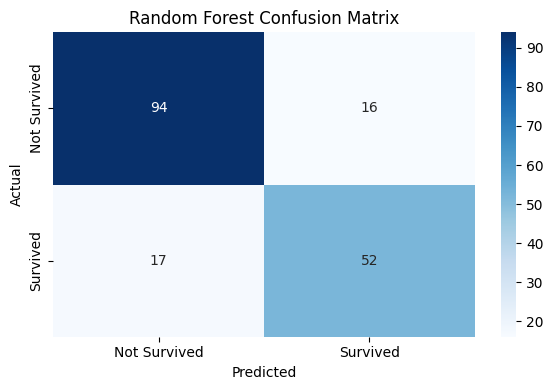


========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.85      0.85      0.85       110
           1       0.76      0.75      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.82      0.82      0.82       179


========== FEATURE IMPORTANCE ==========
num__Fare                  0.243449
num__Age                   0.215423
cat__Title_Mr              0.088814
cat__Sex_male              0.087716
cat__Sex_female            0.076939
num__Pclass                0.070470
num__SibSp                 0.046789
cat__Title_Mrs             0.034248
num__Parch                 0.030757
cat__Title_Miss            0.025251
cat__TicketPrefix_NONE     0.011374
cat__TicketPrefix_STONO    0.009931
cat__Title_Master          0.009075
cat__TicketPrefix_PC       0.007411
cat__TicketPrefix_WC       0.006063
dtype: float64


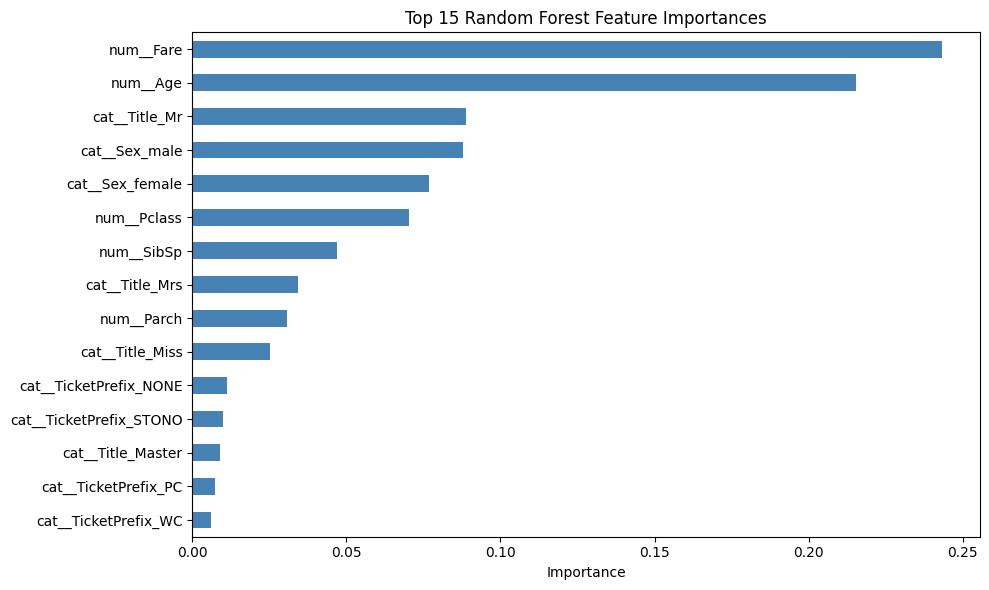

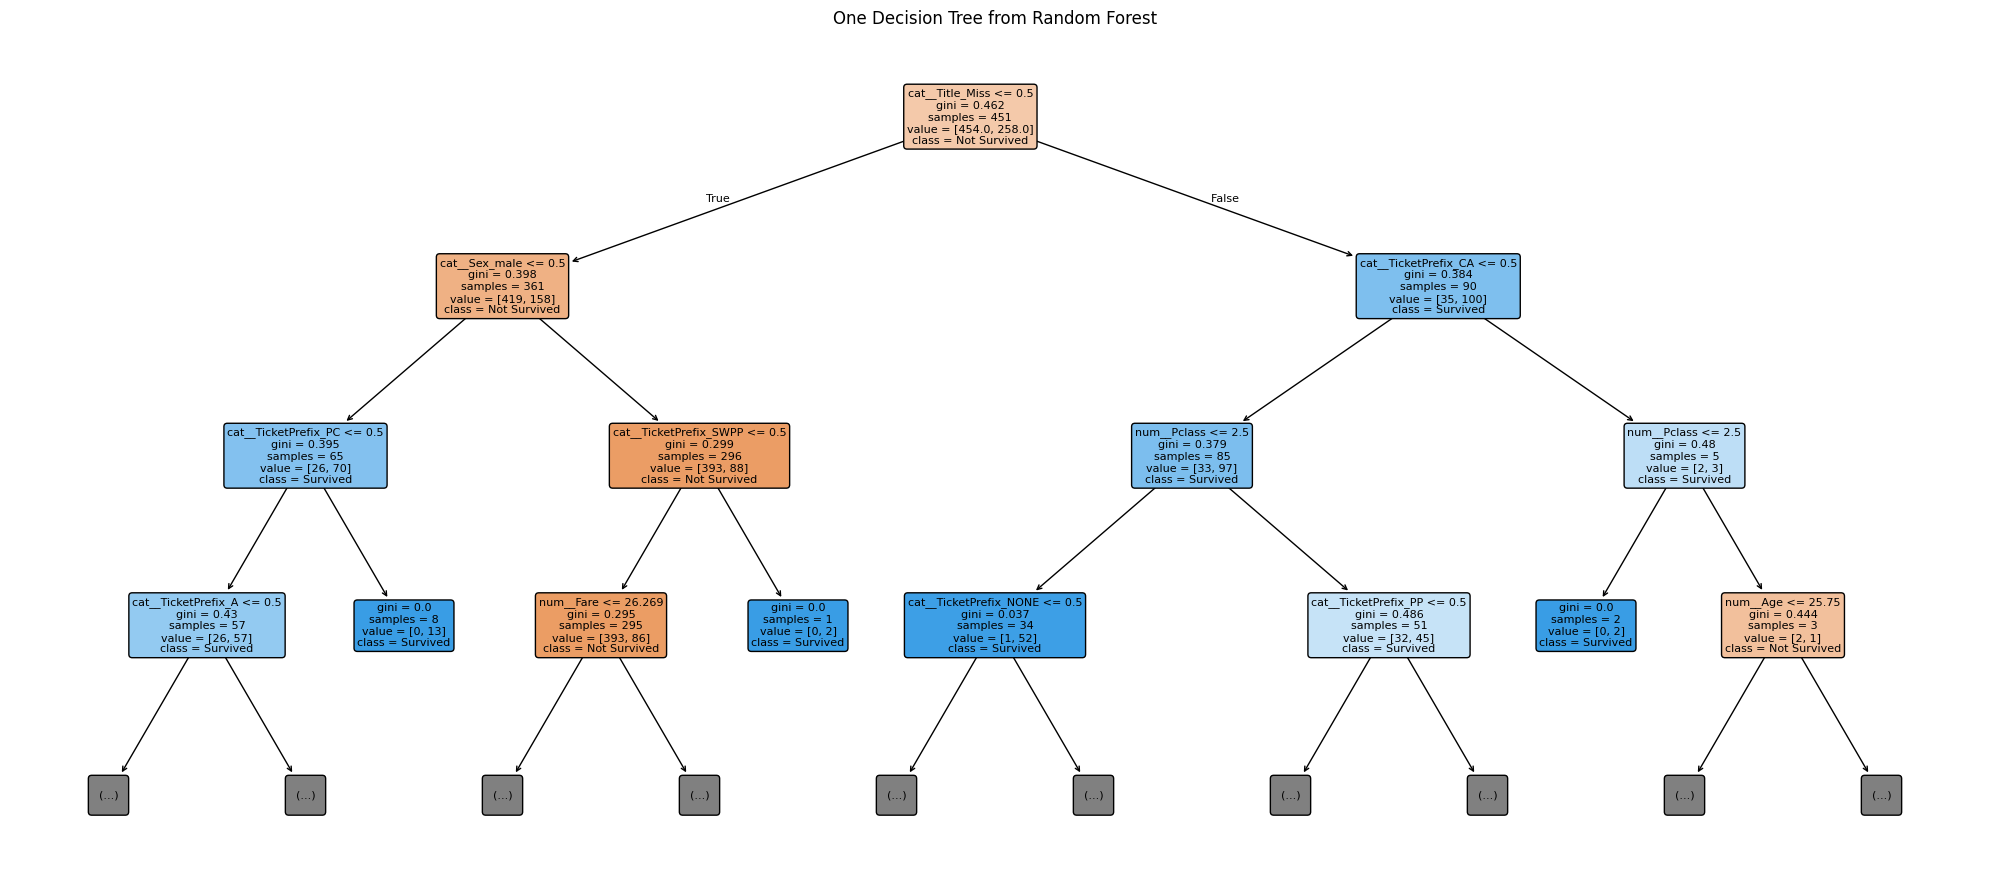


========== MAJORITY VOTING ==========
Total Trees: 100
Survived Votes: 100
Not Survived Votes: 0

First 10 Tree Predictions:
[1 1 1 1 1 1 1 1 1 1]

========== FINAL PREDICTION ==========
Passenger Survived (1)

========== PROJECT COMPLETED ==========


In [ ]:

# ==================================================
# RANDOM FOREST CLASSIFICATION ON TITANIC DATASET
# ==================================================

# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
from sklearn.tree import plot_tree
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# STEP 2: LOAD DATASET

df = pd.read_csv('/content/Titanic-Dataset.csv')

# Remove accidental spaces in column names
df.columns = df.columns.str.strip()

print("\n========== TITANIC DATASET ==========")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())


# STEP 3: DATA PREPROCESSING

# Extract useful information from Name
df['Title'] = df['Name'].str.extract(
    r',\s*([^.]*)\.',
    expand=False
).fillna('Unknown')

# Extract ticket prefix
df['TicketPrefix'] = (
    df['Ticket'].fillna('Unknown')
    .astype(str)
    .str.replace(r'[0-9./\s]', '', regex=True)
    .replace('', 'NONE')
)

# PassengerId is an identifier
# Survived is the target variable
# Name and Ticket are represented by derived features

features = [
    'Pclass', 'Sex', 'Age', 'SibSp',
    'Parch', 'Fare', 'Title', 'TicketPrefix'
]

X = df[features]
y = df['Survived']

print("\nSelected Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())


# STEP 4: CALCULATE ORIGINAL GINI IMPURITY

print("\n========== GINI IMPURITY ==========")

probabilities = y.value_counts(normalize=True)

gini = 1 - sum(probabilities ** 2)

print("Survived:", (y == 1).sum())
print("Not Survived:", (y == 0).sum())
print("Original Gini Impurity:", round(gini, 4))


# STEP 5: BOOTSTRAP SAMPLING EXAMPLE

print("\n========== BOOTSTRAP SAMPLING ==========")

bootstrap_sample = df.sample(
    n=len(df),
    replace=True,
    random_state=42
)

print(bootstrap_sample[
    ['PassengerId', 'Survived']
].head(10))

bootstrap_prob = (
    bootstrap_sample['Survived']
    .value_counts(normalize=True)
)

bootstrap_gini = 1 - sum(bootstrap_prob ** 2)

print("Bootstrap Gini:", round(bootstrap_gini, 4))


# STEP 6: TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# STEP 7: HANDLE MISSING AND CATEGORICAL DATA

numeric_features = [
    'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'
]

categorical_features = [
    'Sex', 'Title', 'TicketPrefix'
]

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])


# STEP 8: CREATE RANDOM FOREST MODEL

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        criterion='gini',
        max_features='sqrt',
        bootstrap=True,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("\nRandom Forest Trained Successfully!")


# STEP 9: PREDICTION

y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

print("\n========== PREDICTIONS ==========")
print(results.head(15))


# STEP 10: MODEL ACCURACY

accuracy = accuracy_score(y_test, y_pred)

print("\n========== ACCURACY ==========")
print(f"Random Forest Accuracy: {accuracy * 100:.2f}%")


# STEP 11: CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.tight_layout()
plt.show()


# STEP 12: CLASSIFICATION REPORT

print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test, y_pred,
    zero_division=0
))


# STEP 13: FEATURE IMPORTANCE

rf = model.named_steps['classifier']

feature_names = (
    model.named_steps['preprocessor']
    .get_feature_names_out()
)

importance = pd.Series(
    rf.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print("\n========== FEATURE IMPORTANCE ==========")
print(importance.head(15))

plt.figure(figsize=(10, 6))

importance.head(15).sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('Top 15 Random Forest Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()


# STEP 14: VISUALIZE ONE DECISION TREE

plt.figure(figsize=(20, 9))

plot_tree(
    rf.estimators_[0],
    feature_names=feature_names,
    class_names=['Not Survived', 'Survived'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title('One Decision Tree from Random Forest')
plt.tight_layout()
plt.show()


# STEP 15: MAJORITY VOTING DEMONSTRATION

print("\n========== MAJORITY VOTING ==========")

new_passenger = pd.DataFrame([{
    'Pclass': 1,
    'Sex': 'female',
    'Age': 28,
    'SibSp': 0,
    'Parch': 0,
    'Fare': 75,
    'Title': 'Miss',
    'TicketPrefix': 'NONE'
}])

transformed_passenger = (
    model.named_steps['preprocessor']
    .transform(new_passenger)
)

tree_votes = np.array([
    int(tree.predict(transformed_passenger)[0])
    for tree in rf.estimators_
])

survived_votes = int(np.sum(tree_votes == 1))
not_survived_votes = int(np.sum(tree_votes == 0))

print("Total Trees:", len(tree_votes))
print("Survived Votes:", survived_votes)
print("Not Survived Votes:", not_survived_votes)

print("\nFirst 10 Tree Predictions:")
print(tree_votes[:10])

final_prediction = model.predict(new_passenger)[0]

print("\n========== FINAL PREDICTION ==========")

if final_prediction == 1:
    print("Passenger Survived (1)")
else:
    print("Passenger Did Not Survive (0)")

print("\n========== PROJECT COMPLETED ==========")
